# Moving MNIST motion forecasting


In [ ]:
# Install the repository requirements in your own environment before running.
import sys
print('Kernel Python:', sys.executable)


## Task 1 


In [ ]:
import io
import json
import platform
import random
import subprocess
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from PIL import Image
from IPython.display import display, Markdown
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader

# Launch from the repository root or Question2_normalized/.
HERE = Path.cwd().resolve()
ROOT = HERE if (HERE / 'Question2_normalized').is_dir() else HERE.parent
assert (ROOT / 'Question2_normalized').is_dir(), 'Start Jupyter from the repository root or Question2_normalized/.'
Q2 = ROOT / 'Question2_normalized'
DATA_ROOT = ROOT / 'data'
ART = Q2 / 'run_artifacts'
for folder in ['checkpoints', 'results', 'figures', 'gifs']:
    (ART / folder).mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('mps' if torch.backends.mps.is_available()
                      else 'cuda' if torch.cuda.is_available() else 'cpu')
# Set DEVICE = torch.device('cpu') here if your Mac does not support MPS.
SEEDS, EPOCHS, BATCH_SIZE, LR = (0, 1), 30, 32, 1e-3
PROTOCOL = dict(version=1, experiment='question2_normalized_v1', epochs=30, batch_size=32, lr=1e-3,
                seeds=[0, 1], train=[0, 8000],
                validation=[8000, 9000], test=[9000, 10000])

# Exact baseline for A-C; larger-reach D with normalized second-layer gates.
D_REVISION = 'dense_k3k5_h54_gate_norm_v3'

def model_config(name):
    return dict(hidden=54, kernels=[3, 5], dilations=[1, 1], layer2_gate_norm=True) if name == 'D' else dict(
        hidden=64, kernels=[3, 3], dilations=[1, 1])

def result_stem(name, seed):
    return f'{name}_seed{seed}'

def sync():
    if DEVICE.type == 'mps':
        torch.mps.synchronize()
    elif DEVICE.type == 'cuda':
        torch.cuda.synchronize()

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

def save_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2))
    tmp.replace(path)

hardware = dict(machine=platform.machine(), system=platform.platform(),
                processor=platform.processor(), device=str(DEVICE),
                torch=torch.__version__, torchvision=torchvision.__version__,
                numpy=np.__version__, opencv=cv2.__version__)
if DEVICE.type == 'cuda':
    hardware['accelerator'] = torch.cuda.get_device_name()
if platform.system() == 'Darwin':
    hardware['cpu_model'] = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string'], text=True).strip()
print(hardware)

print('Experiment directory:', Q2)


In [3]:
# split=None returns complete videos; never use the dataset's built-in frame splits.
data = torchvision.datasets.MovingMNIST(root=str(DATA_ROOT), split=None, download=True)
assert len(data) == 10000 and tuple(data[0].shape) == (20, 1, 64, 64)
assert data[0].dtype == torch.uint8
TRAIN_IDS = list(range(8000))
VAL_IDS = list(range(8000, 9000))
TEST_IDS = list(range(9000, 10000))

def video(index):
    # Normalize one video at a time; do not materialize the full dataset as float32.
    return data[int(index)].to(torch.float32).div(255)

save_json(ART / 'results' / 'setup.json', dict(protocol=PROTOCOL, hardware=hardware,
                                                    D_revision=D_REVISION, D_architecture=model_config('D')))
print('Train / validation / test:', len(TRAIN_IDS), len(VAL_IDS), len(TEST_IDS))


Train / validation / test: 8000 1000 1000


## Task 2 


In [4]:
GROUP = [(a, mirror) for mirror in (False, True) for a in range(4)]
M, R = (0, True), (1, False)

def transform(x, g):
    a, mirror = g
    out = torch.rot90(x, a, dims=(-2, -1))
    return out.flip(-1) if mirror else out

def inverse_transform(x, g):
    a, mirror = g
    return transform(x, g) if mirror else torch.rot90(x, -a, dims=(-2, -1))

def window(v, t=1, k=1):
    assert k in (1, 2, 3) and t >= 1
    inputs = t - 1 + torch.arange(5) * k
    targets = t - 1 + torch.arange(5, 10) * k
    assert inputs[-1] < 20
    valid = targets < 20
    assert valid.sum() >= 2
    y = v.new_zeros((5, *v.shape[1:]))
    y[valid] = v[targets[valid]]
    return v[inputs], y, valid

class Windows(Dataset):
    def __init__(self, ids, model='A', training=False):
        self.ids, self.model, self.training = ids, model, training

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        k, t = 1, 1
        if self.training:
            if self.model in ('C', 'D'):
                k = random.choice((1, 2, 3))
                t = random.randint(1, {1: 14, 2: 8, 3: 2}[k])
            else:
                t = random.randint(1, 11)
        x, y, mask = window(video(self.ids[i]), t, k)
        if self.training and self.model == 'B':
            g = random.choice(GROUP)
            x, y = transform(x, g), transform(y, g)
        return x, y, mask

def horizon_mse(pred, target):
    return (pred - target).square().mean(dim=(2, 3, 4))  # B x 5

def masked_loss(pred, target, mask):
    errors = horizon_mse(pred, target)
    return ((errors * mask).sum(1) / mask.sum(1)).mean()

seed_all(0)
x = torch.rand(20, 1, 64, 64)
p = torch.zeros_like(x)
p[7, 0, 10, 20] = 1
rows = []
for label, lhs, rhs in [
    ('(a) M(M(x)) = x', transform(transform(x, M), M), x),
    ('(b) R^4(x) = x', transform(transform(transform(transform(x, R), R), R), R), x),
    ('(c) MRM(x) = R^-1(x)', transform(transform(transform(x, M), R), M),
     transform(x, (-1, False)))]:
    difference = (lhs - rhs).abs().max().item()
    equal = torch.equal(lhs, rhs)
    assert difference == 0 and equal
    rows.append([label, '0; torch.equal=True', f'{difference:g}; torch.equal={equal}'])
for label, g, expected in [('(d) M(p)', M, (7, 10, 43)),
                           ('(e) R(p)', R, (7, 43, 10))]:
    pos = torch.nonzero(transform(p, g), as_tuple=False)[0].tolist()
    got = (pos[0], pos[2], pos[3])
    assert got == expected
    rows.append([label, str(expected), str(got)])
numbered = torch.arange(1, 21).view(20, 1, 1, 1).expand(20, 1, 64, 64)
expected_frames = [([1,2,3,4,5], [6,7,8,9,10]),
                   ([1,3,5,7,9], [11,13,15,17,19]),
                   ([1,4,7,10,13], [16,19])]
for label, k, expected in zip(('f', 'g', 'h'), (1,2,3), expected_frames):
    xx, yy, valid = window(numbered, 1, k)
    got = (xx[:,0,0,0].tolist(), yy[valid,0,0,0].tolist())
    assert got == expected
    rows.append([f'({label}) {k}x input / target', str(expected), str(got)])
for g in GROUP:
    assert torch.equal(inverse_transform(transform(x, g), g), x)
for k, last in {1:14, 2:8, 3:2}.items():
    for t in range(1, last+1):
        assert window(numbered, t, k)[2].sum() >= 2
# A video with 2 targets must have the same weight as one with 5 targets.
mask = torch.tensor([[1,1,0,0,0], [1,1,1,1,1]], dtype=torch.bool)
pp = torch.zeros(2,5,1,2,2)
yy = torch.stack([torch.ones(5,1,2,2), 3*torch.ones(5,1,2,2)])
assert masked_loss(pp, yy, mask).item() == 5.0
TABLE1_PASSED = True
Table1 = pd.DataFrame(rows, columns=['Check', 'Expected', 'Yours'])
display(Table1)
Table1.to_csv(ART / 'results' / 'Table1.csv', index=False)


,Check,Expected,Yours
0,(a) M(M(x)) = x,0; torch.equal=True,0; torch.equal=True
1,(b) R^4(x) = x,0; torch.equal=True,0; torch.equal=True
2,(c) MRM(x) = R^-1(x),0; torch.equal=True,0; torch.equal=True
3,(d) M(p),"(7, 10, 43)","(7, 10, 43)"
4,(e) R(p),"(7, 43, 10)","(7, 43, 10)"
5,(f) 1x input / target,"([1, 2, 3, 4, 5], [6, 7, 8, 9, 10])","([1, 2, 3, 4, 5], [6, 7, 8, 9, 10])"
6,(g) 2x input / target,"([1, 3, 5, 7, 9], [11, 13, 15, 17, 19])","([1, 3, 5, 7, 9], [11, 13, 15, 17, 19])"
7,(h) 3x input / target,"([1, 4, 7, 10, 13], [16, 19])","([1, 4, 7, 10, 13], [16, 19])"


## Task 3


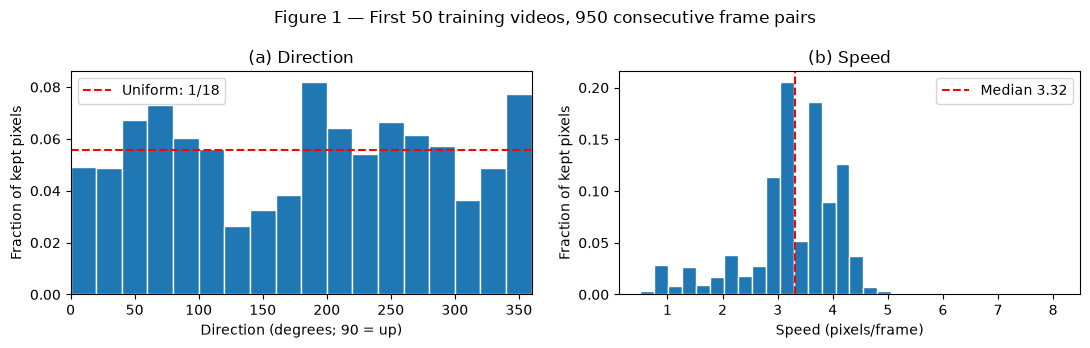

Figure 1: 103,050 kept pixels; median speed 3.32 pixels/frame.
2x / 3x typical displacements: 6.64 / 9.95 pixels/frame


In [5]:
assert TABLE1_PASSED
angles, speeds = [], []
for index in range(50):
    frames = (video(index)[:,0].numpy() * 255).astype(np.uint8)
    for s in range(19):
        prev, nxt = frames[s], frames[s+1]
        flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = flow[...,0], flow[...,1]
        speed = np.hypot(dx, dy)
        keep = (prev > 51) & (nxt > 51) & (speed > 0.5)
        angles.append((np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360))
        speeds.append(speed[keep])
angles, speeds = np.concatenate(angles), np.concatenate(speeds)
assert speeds.size > 0
median_speed = float(np.median(speeds))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
weights = np.full(speeds.size, 1 / speeds.size)
ax[0].hist(angles, bins=np.arange(0,361,20), weights=weights, edgecolor='white')
ax[0].axhline(1/18, color='red', linestyle='--', label='Uniform: 1/18')
ax[0].set(xlabel='Direction (degrees; 90 = up)', ylabel='Fraction of kept pixels',
          title='(a) Direction', xlim=(0,360))
ax[0].legend()
ax[1].hist(speeds, bins=30, weights=weights, edgecolor='white')
ax[1].axvline(median_speed, color='red', linestyle='--', label=f'Median {median_speed:.3g}')
ax[1].set(xlabel='Speed (pixels/frame)', ylabel='Fraction of kept pixels', title='(b) Speed')
ax[1].legend()
fig.suptitle('Figure 1 — First 50 training videos, 950 consecutive frame pairs')
fig.tight_layout()
fig.savefig(ART / 'figures' / 'Figure1.png', dpi=180, bbox_inches='tight')
plt.show()
caption = f'Figure 1: {speeds.size:,} kept pixels; median speed {median_speed:.3g} pixels/frame.'
print(caption)
print(f'2x / 3x typical displacements: {2*median_speed:.3g} / {3*median_speed:.3g} pixels/frame')
(ART / 'figures' / 'Figure1-caption.txt').write_text(caption)
np.savez_compressed(ART / 'results' / 'flow.npz', angles=angles, speeds=speeds)


## Task 4


In [6]:
class ConvLSTMCell(nn.Module):
    def __init__(self, inputs, hidden=64, kernel_size=3, dilation=1, gate_norm=False):
        super().__init__()
        self.hidden = hidden
        self.gates = nn.Conv2d(inputs + hidden, 4 * hidden, kernel_size,
                               padding=(kernel_size // 2) * dilation,
                               dilation=dilation, bias=True)

        self.norm = nn.LayerNorm(4 * hidden) if gate_norm else None

    def forward(self, u, state):
        h, c = state
        logits = self.gates(torch.cat([u, h], dim=1))
        if self.norm is not None:
            # Normalize channels at each location, never across space, time or batch.
            logits = self.norm(logits.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)
        i, f, o, g = logits.chunk(4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

class Forecaster(nn.Module):
    def __init__(self, name='A'):
        super().__init__()
        config = model_config(name)
        self.hidden = config['hidden']
        k1, k2 = config['kernels']
        d1, d2 = config['dilations']
        self.cell1 = ConvLSTMCell(16, self.hidden, k1, d1)
        self.cell2 = ConvLSTMCell(self.hidden, self.hidden, k2, d2,
                                  gate_norm=config.get('layer2_gate_norm', False))
        self.head = nn.Conv2d(self.hidden, 16, 1, bias=True)

    def forward(self, x):
        assert x.ndim == 5 and tuple(x.shape[1:]) == (5,1,64,64)
        zero = x.new_zeros((x.shape[0], self.hidden, 16, 16))
        state1 = (zero, zero.clone())
        state2 = (zero.clone(), zero.clone())
        outputs = []
        pred = None
        for step in range(9):
            frame = x[:,step] if step < 5 else pred
            state1 = self.cell1(F.pixel_unshuffle(frame, 4), state1)
            state2 = self.cell2(state1[0], state2)
            pred = torch.sigmoid(F.pixel_shuffle(self.head(state2[0]), 4))
            if step >= 4:
                outputs.append(pred)
        return torch.stack(outputs, dim=1)

class Reference(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.kind = kind

    def forward(self, x):
        return torch.zeros_like(x) if self.kind == 'Blank' else x[:,-1:].expand(-1,5,-1,-1,-1)

def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

assert parameter_count(Forecaster('A')) == 480784
assert parameter_count(Forecaster('D')) == 721024 <= 721176
print('A parameters:', f"{parameter_count(Forecaster('A')):,}", '; reach 8 pixels per axis')
print('D parameters:', f"{parameter_count(Forecaster('D')):,}", '; reach 12 pixels per axis')


A parameters: 480,784 ; reach 8 pixels per axis
D parameters: 721,024 ; reach 12 pixels per axis


## Task 5


In [7]:
def checkpoint_path(name, seed):
    return ART / 'checkpoints' / f'{result_stem(name, seed)}.pt'

def load_checkpoint(name, seed):
    # Only load checkpoints created locally by this notebook.
    ck = torch.load(checkpoint_path(name, seed), map_location='cpu', weights_only=False)
    assert ck['protocol'] == PROTOCOL, 'Checkpoint belongs to a different protocol/experiment.'
    assert ck.get('architecture') == model_config(name), 'Checkpoint architecture mismatch.'
    assert ck['name'] == name and ck['seed'] == seed
    return ck



def train_model(name, seed):
    assert TABLE1_PASSED and name in ('A','B','C','D') and seed in SEEDS
    seed_all(seed)
    model = Forecaster(name).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    first, history, times = 0, [], []
    path = checkpoint_path(name, seed)
    if path.exists():
        ck = load_checkpoint(name, seed)
        model.load_state_dict(ck['model'])
        optimizer.load_state_dict(ck['optimizer'])
        # torch.load(map_location='cpu') also maps Adam moments to CPU.
        for state in optimizer.state.values():
            for key in ('exp_avg', 'exp_avg_sq', 'max_exp_avg_sq'):
                if key in state:
                    state[key] = state[key].to(DEVICE)
        first, history, times = ck['epoch'], ck['loss'], ck['epoch_seconds']
        if first == EPOCHS:
            print(f'{name}, seed {seed}: using saved epoch 30 weights')
            return model.eval()
    else:
        ck = dict(hardware=hardware)
    assert ck['hardware'] == hardware, 'Resume on the same hardware for consistent timing.'
    for epoch in range(first, EPOCHS):
        seed_all(seed + 1009 * epoch)
        generator = torch.Generator().manual_seed(seed + 1009 * epoch)
        loader = DataLoader(Windows(TRAIN_IDS, name, training=True), batch_size=BATCH_SIZE,
                            shuffle=True, generator=generator, num_workers=0)
        model.train()
        total = 0.0
        sync()
        start = time.perf_counter()
        for x, y, mask in loader:
            x, y, mask = x.to(DEVICE), y.to(DEVICE), mask.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = masked_loss(model(x), y, mask)
            loss.backward()
            optimizer.step()
            total += loss.detach().item() * x.shape[0]
        sync()
        times.append(time.perf_counter() - start)
        history.append(total / len(TRAIN_IDS))
        ck = dict(protocol=PROTOCOL, name=name, seed=seed, epoch=epoch+1,
                  model=model.state_dict(), optimizer=optimizer.state_dict(),
                  loss=history, epoch_seconds=times, hardware=hardware,
                  architecture=model_config(name))
        tmp = path.with_suffix('.tmp')
        torch.save(ck, tmp)
        tmp.replace(path)
        print(f'{name} seed {seed} | epoch {epoch+1:02d}/30 | MSE {history[-1]:.6g} | {times[-1]:.1f}s')
    return model.eval()

def trained(name, seed=0):
    ck = load_checkpoint(name, seed)
    assert ck['epoch'] == EPOCHS, f'{name} seed {seed}: training not finished.'
    model = Forecaster(name).to(DEVICE)
    model.load_state_dict(ck['model'])
    return model.eval()


## Task 6

In [8]:
@torch.no_grad()
def evaluate(model, k=1, spatial=False, ids=None):
    ids = TEST_IDS if ids is None else list(ids)
    model.eval()
    values = {f'MSE{h}': [] for h in range(1,6) if 1+(4+h)*k <= 20}
    if spatial:
        assert k == 1
        values.update({key: [] for key in ('CM','EM','CR','ER')})
    elapsed = 0.0
    for offset in range(0, len(ids), BATCH_SIZE):
        batch = [window(video(i), 1, k) for i in ids[offset:offset+BATCH_SIZE]]
        x, y, mask = [torch.stack(items).to(DEVICE) for items in zip(*batch)]
        sync()
        start = time.perf_counter()
        pred = model(x)
        sync()
        elapsed += time.perf_counter() - start
        errors = horizon_mse(pred, y).cpu().numpy()
        for h in range(int(mask[0].sum())):
            values[f'MSE{h+1}'].append(errors[:,h])
        if spatial:
            for label, g in [('M',M), ('R',R)]:
                transformed_pred = model(transform(x, g))
                gap = horizon_mse(transformed_pred, transform(pred, g)).mean(1)
                error = horizon_mse(transformed_pred, transform(y, g)).mean(1)
                values['C'+label].append(gap.cpu().numpy())
                values['E'+label].append(error.cpu().numpy())
    values = {key: np.concatenate(parts) for key, parts in values.items()}
    values['E2'] = np.stack([values['MSE1'], values['MSE2']]).mean(0)
    if k < 3:
        values['E5'] = np.stack([values[f'MSE{h}'] for h in range(1,6)]).mean(0)
    assert all(v.shape == (len(ids),) for v in values.values())
    return values, elapsed

metrics = {}
def measure(name, seed=0, full=True):
    required = {'E5_1x', 'parameters', 'train_s_epoch', 'inference_s'}
    if full:
        required.update({'CM_1x', 'EM_1x', 'CR_1x', 'ER_1x', 'E2_2x', 'E2_3x'})
    if (name, seed) in metrics and required <= metrics[(name, seed)].keys():
        print(f'{name}, seed {seed}: using saved metrics')
        return metrics[(name, seed)]
    wrapped = name.startswith('Sym-')
    base = name.removeprefix('Sym-')
    model = Reference(name).to(DEVICE) if name in ('Blank','Copy-last') else trained(base, seed)
    if wrapped:
        model = Symmetrised(model).to(DEVICE)
    result = {}
    for k in ((1,2,3) if full else (1,)):
        raw, seconds = evaluate(model, k=k, spatial=full and k == 1)
        result.update({f'{key}_{k}x': float(v.mean()) for key,v in raw.items()})
        if k == 1:
            result['inference_s'] = seconds
        np.savez_compressed(ART / 'results' / f'{result_stem(name, seed)}_{k}x.npz',
                            video_ids=np.array(TEST_IDS), **raw)
    result['parameters'] = parameter_count(model)
    result['train_s_epoch'] = (0.0 if name in ('Blank','Copy-last') else
                               float(np.mean(load_checkpoint(base, seed)['epoch_seconds'])))
    metrics[(name,seed)] = result
    save_json(ART / 'results' / f'{result_stem(name, seed)}_metrics.json', result)
    return result

def restore_metrics():
    # Resume only this experiment; the artifact directory is empty on its first run.
    for name in ('A','B','C','D','Sym-B','Sym-D','Blank','Copy-last'):
        for seed in ((0,) if name in ('Blank','Copy-last') else SEEDS):
            path = ART / 'results' / f'{result_stem(name, seed)}_metrics.json'
            if path.exists():
                metrics[(name, seed)] = json.loads(path.read_text())
restore_metrics()


def format_number(x, scientific=False):
    return f'{x:.2e}' if scientific or (abs(x) < 1e-3) else f'{x:#.3g}'

def table(number, names, columns):
    rows = []
    for name in names:
        seeds = (0,) if name in ('Blank','Copy-last') else SEEDS
        row = {'Model': name}
        for label, key in columns:
            vals = [metrics[(name,s)][key] for s in seeds]
            sci = name.startswith('Sym-') and key in ('CM_1x','CR_1x')
            if key == 'parameters':
                assert all(int(v) == int(vals[0]) for v in vals), 'Parameter count must agree across seeds.'
                row[label] = f'{int(vals[0]):,}'
                continue
            fmt = lambda v: format_number(v, sci)
            row[label] = (fmt(vals[0]) if len(vals)==1 else
                          f'{fmt(np.mean(vals))} ({fmt(vals[0])}, {fmt(vals[1])})')
        rows.append(row)
    frame = pd.DataFrame(rows)
    print(f'Table {number} — metrics/timings: mean (seed 0, seed 1); parameters: integer; times: seconds')
    display(frame)
    frame.to_csv(ART / 'results' / f'Table{number}.csv', index=False)
    return frame

T5_COLUMNS = [('E5 1x','E5_1x'), ('CM','CM_1x'), ('EM','EM_1x'),
              ('CR','CR_1x'), ('ER','ER_1x'), ('E2 1x','E2_1x'),
              ('E2 2x','E2_2x'), ('E2 3x','E2_3x'), ('Parameters','parameters'),
              ('Train s/epoch','train_s_epoch'), ('Inference s','inference_s')]

@torch.no_grad()
def predict_one(model, index, k=1):
    x, y, valid = window(video(index), 1, k)
    pred = model(x.unsqueeze(0).to(DEVICE))[0].cpu()
    return x, pred, y, valid

def frame_grid(rows, labels, title, path=None, columns=None):
    n = len(rows[0])
    assert all(len(row) == n for row in rows)
    fig, axes = plt.subplots(len(rows), n, figsize=(1.25*n, 1.45*len(rows)), squeeze=False)
    for r, images in enumerate(rows):
        for c, im in enumerate(images):
            axes[r,c].imshow(torch.as_tensor(im).squeeze().cpu().numpy(), cmap='gray', vmin=0, vmax=1)
            axes[r,c].set_xticks([])
            axes[r,c].set_yticks([])
            if c == 0:
                axes[r,c].set_ylabel(labels[r], fontsize=8)
            if r == 0 and columns:
                axes[r,c].set_title(columns[c], fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return fig

def preview_videos(ids, frames=range(1,21)):
    frames = list(frames)
    frame_grid([video(i)[np.array(frames)-1] for i in ids],
               [str(i) for i in ids], 'True frames: inspect digit overlaps',
               columns=[str(f) for f in frames])


## Task 7 

In [9]:
for seed in SEEDS:
    model = train_model('A', seed)
    del model
for name in ('A', 'Blank', 'Copy-last'):
    for seed in (SEEDS if name == 'A' else (0,)):
        measure(name, seed, full=False)
Table2 = table(2, ['A','Blank','Copy-last'],
               [(f'MSE{h}',f'MSE{h}_1x') for h in range(1,6)] +
               [('E5','E5_1x'), ('Parameters','parameters')])


A seed 0 | epoch 01/30 | MSE 0.0460453 | 25.0s
A seed 0 | epoch 02/30 | MSE 0.0396916 | 24.3s
A seed 0 | epoch 03/30 | MSE 0.0386419 | 24.4s
A seed 0 | epoch 04/30 | MSE 0.0370822 | 24.3s
A seed 0 | epoch 05/30 | MSE 0.0352214 | 24.5s
A seed 0 | epoch 06/30 | MSE 0.0335348 | 27.5s
A seed 0 | epoch 07/30 | MSE 0.0321609 | 34.8s
A seed 0 | epoch 08/30 | MSE 0.0310689 | 37.2s
A seed 0 | epoch 09/30 | MSE 0.0301953 | 38.2s
A seed 0 | epoch 10/30 | MSE 0.0297079 | 38.6s
A seed 0 | epoch 11/30 | MSE 0.0292157 | 38.9s
A seed 0 | epoch 12/30 | MSE 0.028717 | 33.8s
A seed 0 | epoch 13/30 | MSE 0.0282801 | 31.2s
A seed 0 | epoch 14/30 | MSE 0.0279885 | 31.6s
A seed 0 | epoch 15/30 | MSE 0.0275626 | 31.8s
A seed 0 | epoch 16/30 | MSE 0.0272093 | 32.7s
A seed 0 | epoch 17/30 | MSE 0.0267723 | 33.4s
A seed 0 | epoch 18/30 | MSE 0.0263777 | 36.0s
A seed 0 | epoch 19/30 | MSE 0.0259929 | 35.5s
A seed 0 | epoch 20/30 | MSE 0.02558 | 36.7s
A seed 0 | epoch 21/30 | MSE 0.0252012 | 35.7s
A seed 0 | epoch

,Model,MSE1,MSE2,MSE3,MSE4,MSE5,E5,Parameters
0,A,"0.0170 (0.0176, 0.0164)","0.0204 (0.0208, 0.0200)","0.0228 (0.0231, 0.0225)","0.0247 (0.0249, 0.0245)","0.0265 (0.0265, 0.0265)","0.0223 (0.0226, 0.0220)","480,784"
1,Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
2,Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0


### Figure 2


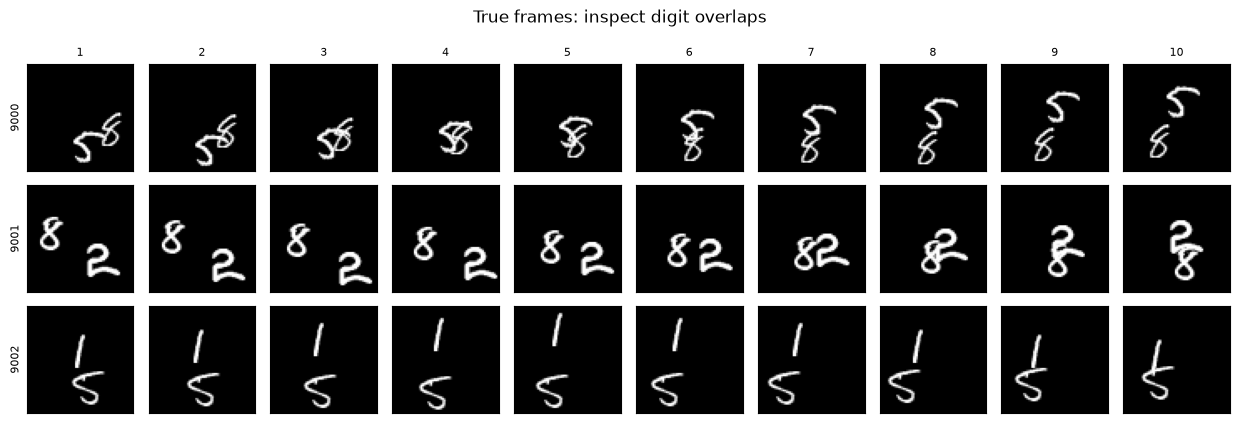

In [10]:
FIG2_IDS = [9000, 9001, 9002]
preview_videos(FIG2_IDS, frames=range(1,11))


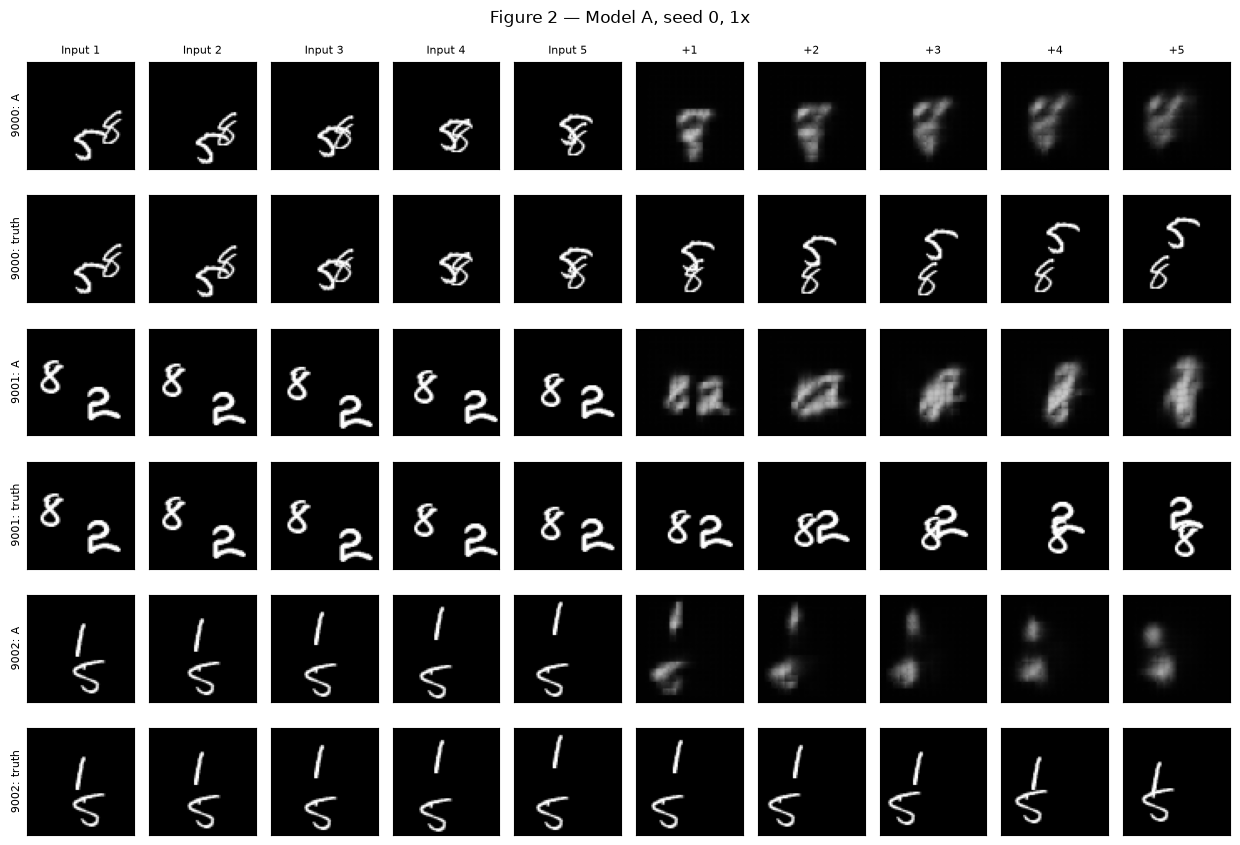

In [11]:
FIG2_OVERLAP_CONFIRMED = True  # Set True after checking that at least one clip has overlap.
assert FIG2_OVERLAP_CONFIRMED, 'Inspect/change FIG2_IDS, then confirm an overlap example.'
assert len(set(FIG2_IDS)) == 3 and all(i in TEST_IDS for i in FIG2_IDS)
a0 = trained('A', 0)
rows, labels = [], []
for i in FIG2_IDS:
    x, pred, y, _ = predict_one(a0, i)
    rows.extend([torch.cat([x,pred]), torch.cat([x,y])])
    labels.extend([f'{i}: A', f'{i}: truth'])
frame_grid(rows, labels, 'Figure 2 — Model A, seed 0, 1x',
           ART / 'figures' / 'Figure2.png',
           columns=[f'Input {h}' for h in range(1,6)] + [f'+{h}' for h in range(1,6)])
save_json(ART / 'results' / 'figure2_ids.json', FIG2_IDS)


## Task 8 

In [12]:
for name in ('A','Blank','Copy-last'):
    for seed in (SEEDS if name == 'A' else (0,)):
        measure(name, seed, full=True)
Table3 = table(3, ['A','Blank','Copy-last'],
               [('E5','E5_1x'), ('CM','CM_1x'), ('EM','EM_1x'), ('CR','CR_1x'), ('ER','ER_1x')])
Table4 = table(4, ['A','Copy-last'],
               [('E2 1x','E2_1x'), ('E2 2x','E2_2x'), ('E2 3x','E2_3x'),
                ('E5 1x','E5_1x'), ('E5 2x','E5_2x')])


Table 3 — metrics/timings: mean (seed 0, seed 1); parameters: integer; times: seconds


,Model,E5,CM,EM,CR,ER
0,A,"0.0223 (0.0226, 0.0220)","0.00196 (0.00189, 0.00202)","0.0229 (0.0233, 0.0226)","0.00332 (0.00367, 0.00298)","0.0241 (0.0245, 0.0237)"
1,Blank,0.0426,0.00e+00,0.0426,0.00e+00,0.0426
2,Copy-last,0.0641,0.00e+00,0.0641,0.00e+00,0.0641


Table 4 — metrics/timings: mean (seed 0, seed 1); parameters: integer; times: seconds


,Model,E2 1x,E2 2x,E2 3x,E5 1x,E5 2x
0,A,"0.0187 (0.0192, 0.0182)","0.0445 (0.0445, 0.0446)","0.0522 (0.0527, 0.0518)","0.0223 (0.0226, 0.0220)","0.0496 (0.0501, 0.0490)"
1,Copy-last,0.0548,0.0661,0.0703,0.0641,0.0719


### Figures 3–4


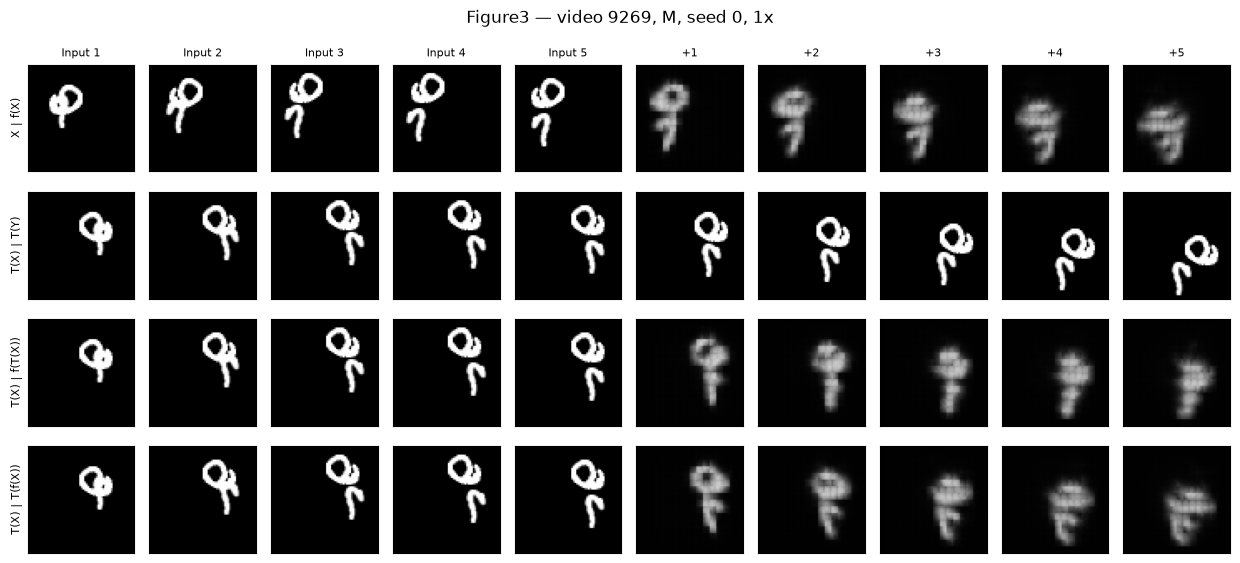

Figure3, video 9269, transformation M, 1x, seed 0. GIF: Question2_normalized/artifacts/gifs/Figure3_M_video9269.gif


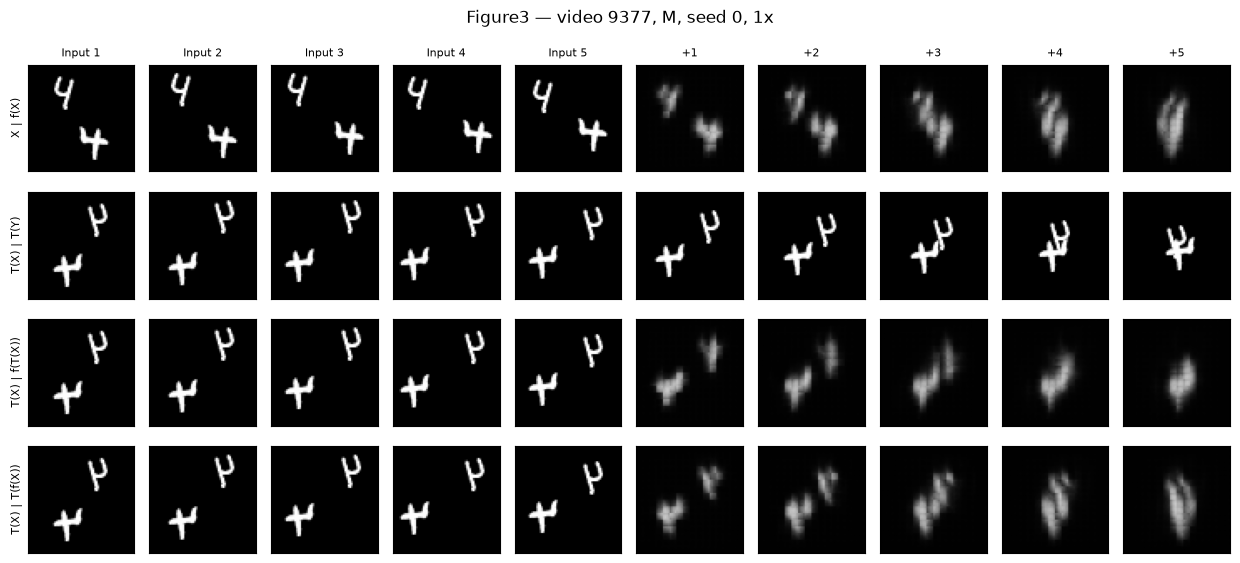

Figure3, video 9377, transformation M, 1x, seed 0. GIF: Question2_normalized/artifacts/gifs/Figure3_M_video9377.gif


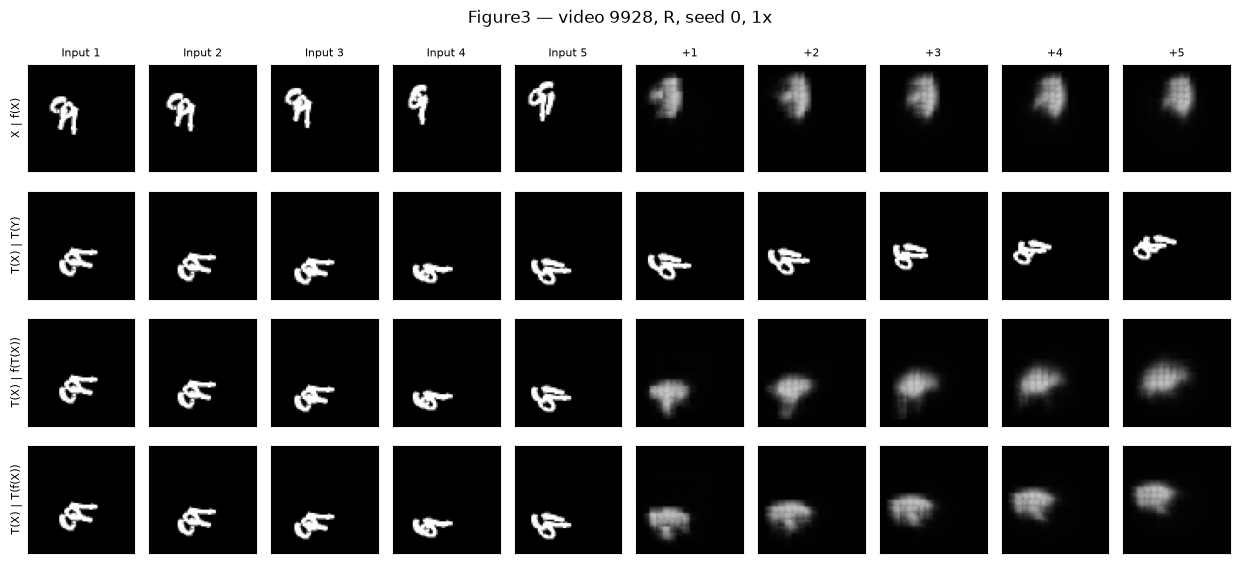

Figure3, video 9928, transformation R, 1x, seed 0. GIF: Question2_normalized/artifacts/gifs/Figure3_R_video9928.gif


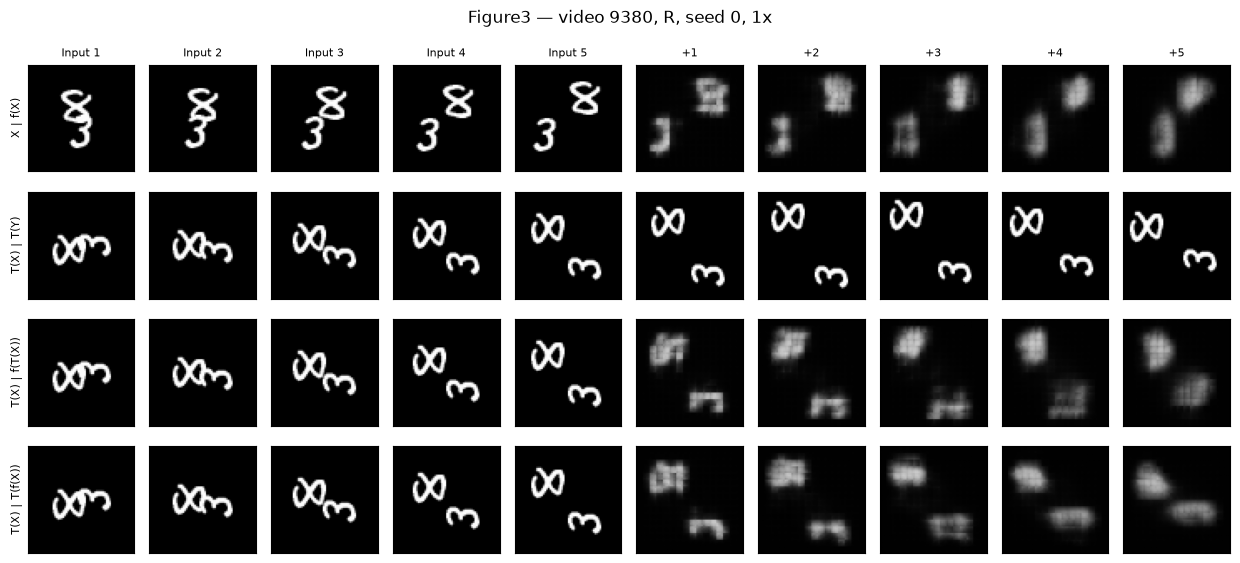

Figure3, video 9380, transformation R, 1x, seed 0. GIF: Question2_normalized/artifacts/gifs/Figure3_R_video9380.gif


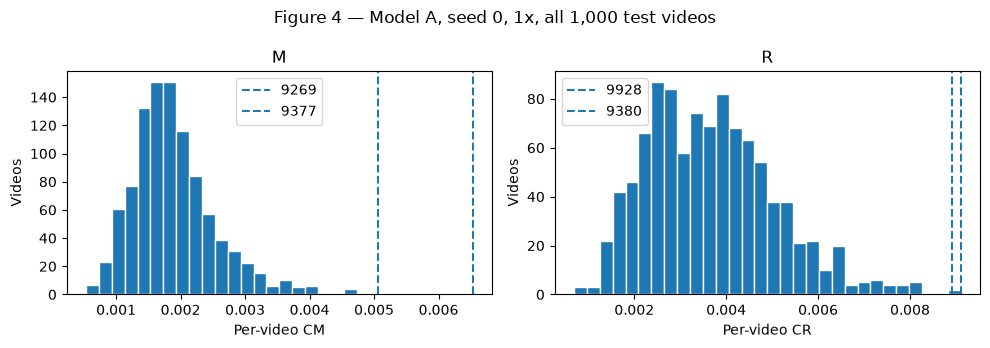

In [13]:
def save_panel_gif(rows, labels, path):
    # Each row: five input frames followed by five future frames.
    # Keep inputs fixed on the left; animate the horizon on the right.
    frames = []
    for h in range(5):
        fig, axes = plt.subplots(4, 6, figsize=(7.5, 5.8), squeeze=False)
        for r in range(4):
            for c in range(6):
                im = rows[r][c if c < 5 else 5+h]
                axes[r,c].imshow(im.squeeze().cpu(), cmap='gray', vmin=0, vmax=1)
                axes[r,c].set_xticks([])
                axes[r,c].set_yticks([])
                if c == 0:
                    axes[r,c].set_ylabel(labels[r], fontsize=8)
                if r == 0:
                    axes[r,c].set_title(f'Input {c+1}' if c < 5 else f'Future +{h+1}', fontsize=8)
        fig.tight_layout()
        buf = io.BytesIO()
        fig.savefig(buf, format='png', dpi=90)
        plt.close(fig)
        buf.seek(0)
        frames.append(Image.open(buf).convert('RGB').copy())
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=650, loop=0)

@torch.no_grad()
def consistency_panel(model, index, label, figure):
    g = M if label == 'M' else R
    x, pred, y, _ = predict_one(model, index)
    tx = transform(x, g)
    tp = model(tx.unsqueeze(0).to(DEVICE))[0].cpu()
    rows = [torch.cat([x,pred]), torch.cat([tx,transform(y,g)]),
            torch.cat([tx,tp]), torch.cat([tx,transform(pred,g)])]
    labels = ['X | f(X)', 'T(X) | T(Y)', 'T(X) | f(T(X))', 'T(X) | T(f(X))']
    stem = f'{figure}_{label}_video{index}'
    gif = ART / 'gifs' / f'{stem}.gif'
    frame_grid(rows, labels, f'{figure} — video {index}, {label}, seed 0, 1x',
               ART / 'figures' / f'{stem}.png',
               columns=[f'Input {h}' for h in range(1,6)] + [f'+{h}' for h in range(1,6)])
    save_panel_gif(rows, labels, gif)
    caption = f'{figure}, video {index}, transformation {label}, 1x, seed 0. GIF: {gif.relative_to(ROOT)}'
    print(caption)
    (ART / 'figures' / f'{stem}-caption.txt').write_text(caption)

rawA = np.load(ART / 'results' / 'A_seed0_1x.npz')
selections = []
for label in ('M','R'):
    # stable order gives reproducible tie handling.
    top = np.argsort(-rawA['C'+label], kind='stable')[:2]
    selections.extend([{'video': int(TEST_IDS[j]), 'transform': label} for j in top])
selection_path = ART / 'results' / 'selections.json'
if selection_path.exists():
    assert json.loads(selection_path.read_text())['figure3'] == selections, 'Keep original Figure 3 selections.'
else:
    save_json(selection_path, {'figure3': selections})
a0 = trained('A', 0)
for item in selections:
    consistency_panel(a0, item['video'], item['transform'], 'Figure3')
fig, axes = plt.subplots(1,2, figsize=(10,3.5))
for ax, label in zip(axes, ('M','R')):
    ax.hist(rawA['C'+label], bins=30, edgecolor='white')
    for item in selections:
        if item['transform'] == label:
            j = item['video'] - 9000
            ax.axvline(rawA['C'+label][j], linestyle='--', label=str(item['video']))
    ax.set(xlabel='Per-video C'+label, ylabel='Videos', title=label)
    ax.legend()
fig.suptitle('Figure 4 — Model A, seed 0, 1x, all 1,000 test videos')
fig.tight_layout()
fig.savefig(ART / 'figures' / 'Figure4.png', dpi=180, bbox_inches='tight')
plt.show()


### Figure 5 


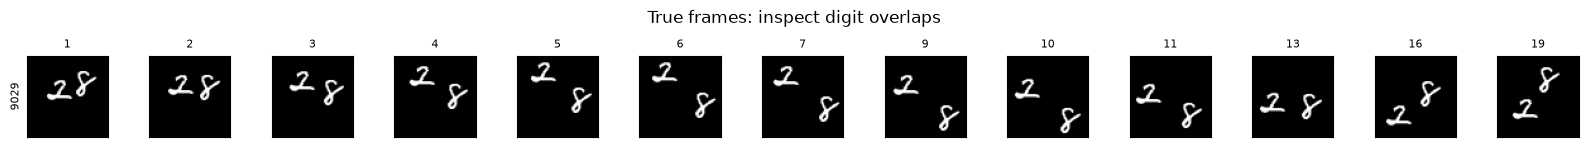

In [14]:
FIG5_ID = 9029 # Change after inspecting the preview if needed.
assert FIG5_ID in TEST_IDS
shown_frames = sorted({1+j*k for k in (1,2,3) for j in range(7)})
preview_videos([FIG5_ID], shown_frames)


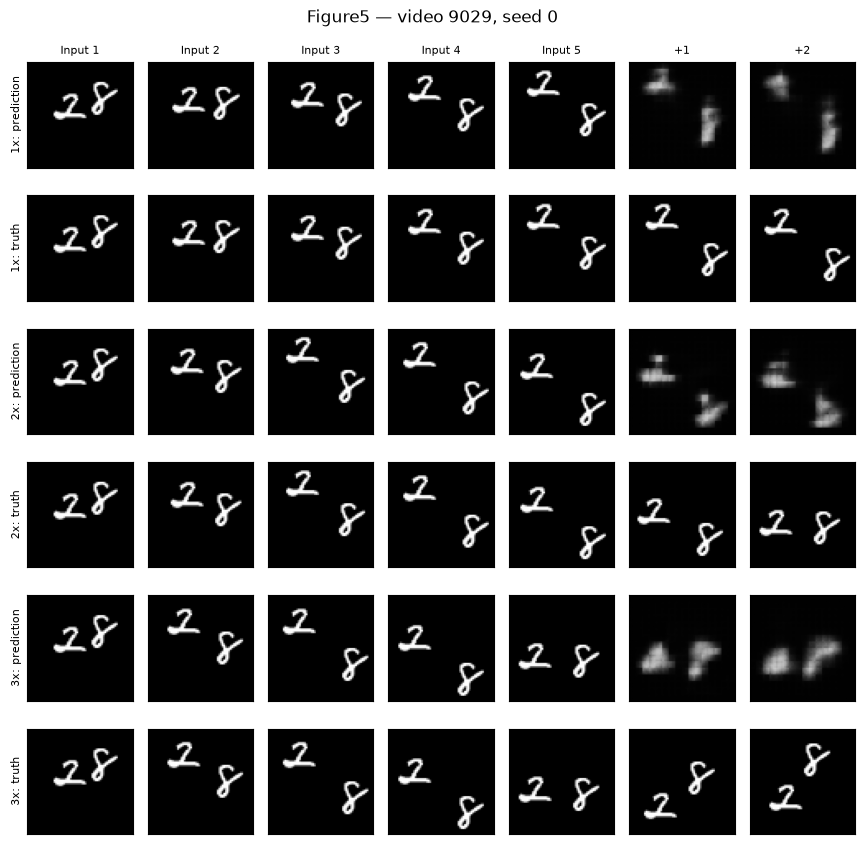

In [15]:
FIG5_NO_OVERLAP_CONFIRMED = True  # Set True only after checking all previewed frames.
assert FIG5_NO_OVERLAP_CONFIRMED, 'Choose a video with no overlaps in displayed true frames.'
manifest = json.loads(selection_path.read_text())
if 'figure5' in manifest:
    assert manifest['figure5'] == FIG5_ID, 'Reuse the original Figure 5 video.'
manifest['figure5'] = FIG5_ID
save_json(selection_path, manifest)

@torch.no_grad()
def speed_panel(model, index, figure):
    rows, labels = [], []
    for k in (1,2,3):
        x, pred, y, _ = predict_one(model, index, k)
        rows.extend([torch.cat([x,pred[:2]]), torch.cat([x,y[:2]])])
        labels.extend([f'{k}x: prediction', f'{k}x: truth'])
    frame_grid(rows, labels, f'{figure} — video {index}, seed 0',
               ART / 'figures' / f'{figure}.png',
               columns=[f'Input {h}' for h in range(1,6)] + ['+1','+2'])
speed_panel(trained('A',0), FIG5_ID, 'Figure5')


## Task 9 

## Task 10 


In [16]:
# First execution trains B, C and D from random initialization for both seeds.
for name in ('B','C','D'):
    for seed in SEEDS:
        model = train_model(name, seed)
        del model
        if name != 'D':
            measure(name, seed, full=True)

# Validation-only comparison, completed before D test evaluation.
validation = {'revision': D_REVISION, 'architecture': model_config('D'),
              'video_ids': VAL_IDS, 'scores': {}}
for name in ('C','D'):
    for seed in SEEDS:
        model = trained(name, seed)
        scores = {}
        for k in (1,2,3):
            raw, _ = evaluate(model, k=k, ids=VAL_IDS)
            scores[f'E2_{k}x'] = float(raw['E2'].mean())
            if k == 1:
                scores['E5_1x'] = float(raw['E5'].mean())
            np.savez_compressed(
                ART / 'results' / f'{result_stem(name, seed)}_validation_{k}x.npz',
                video_ids=np.array(VAL_IDS), **raw)
        validation['scores'][f'{name}_seed{seed}'] = scores
        del model
save_json(ART / 'results' / f'D_{D_REVISION}_validation.json', validation)
validation_rows = []
for name in ('C','D'):
    for seed in SEEDS:
        validation_rows.append({'Model': name, 'Seed': seed,
                                **validation['scores'][f'{name}_seed{seed}']})
print('Validation diagnostics (not report test metrics):')
display(pd.DataFrame(validation_rows))

# Fixed D: report on the test split only after the validation diagnostic.
for seed in SEEDS:
    measure('D', seed, full=True)
Table5 = table(5, ['A','B','C','D'], T5_COLUMNS)


B seed 0 | epoch 01/30 | MSE 0.0460457 | 36.8s
B seed 0 | epoch 02/30 | MSE 0.0396568 | 36.3s
B seed 0 | epoch 03/30 | MSE 0.0386445 | 43.1s
B seed 0 | epoch 04/30 | MSE 0.0370907 | 35.6s
B seed 0 | epoch 05/30 | MSE 0.0352509 | 36.5s
B seed 0 | epoch 06/30 | MSE 0.0335448 | 43.6s
B seed 0 | epoch 07/30 | MSE 0.0322339 | 36.3s
B seed 0 | epoch 08/30 | MSE 0.0312943 | 35.6s
B seed 0 | epoch 09/30 | MSE 0.0305502 | 37.1s
B seed 0 | epoch 10/30 | MSE 0.0299649 | 47.1s
B seed 0 | epoch 11/30 | MSE 0.0294519 | 44.1s
B seed 0 | epoch 12/30 | MSE 0.0289983 | 37.3s
B seed 0 | epoch 13/30 | MSE 0.0286856 | 36.3s
B seed 0 | epoch 14/30 | MSE 0.0283207 | 41.1s
B seed 0 | epoch 15/30 | MSE 0.0280689 | 43.6s
B seed 0 | epoch 16/30 | MSE 0.0276905 | 40.5s
B seed 0 | epoch 17/30 | MSE 0.0273468 | 41.3s
B seed 0 | epoch 18/30 | MSE 0.0271561 | 39.1s
B seed 0 | epoch 19/30 | MSE 0.0268047 | 36.1s
B seed 0 | epoch 20/30 | MSE 0.0262869 | 36.3s
B seed 0 | epoch 21/30 | MSE 0.0261277 | 36.2s
B seed 0 | ep

,Model,Seed,E2_1x,E5_1x,E2_2x,E2_3x
0,C,0,0.024319,0.027897,0.029165,0.033273
1,C,1,0.022710,0.026189,0.028443,0.032735
2,D,0,0.015989,0.019560,0.022357,0.027399
3,D,1,0.015766,0.019231,0.022204,0.026925


Table 5 — metrics/timings: mean (seed 0, seed 1); parameters: integer; times: seconds


,Model,E5 1x,CM,EM,CR,ER,E2 1x,E2 2x,E2 3x,Parameters,Train s/epoch,Inference s
0,A,"0.0223 (0.0226, 0.0220)","0.00196 (0.00189, 0.00202)","0.0229 (0.0233, 0.0226)","0.00332 (0.00367, 0.00298)","0.0241 (0.0245, 0.0237)","0.0187 (0.0192, 0.0182)","0.0445 (0.0445, 0.0446)","0.0522 (0.0527, 0.0518)","480,784","35.6 (32.9, 38.4)","1.05 (1.06, 1.05)"
1,B,"0.0227 (0.0232, 0.0222)","0.00107 (0.00112, 0.00103)","0.0227 (0.0232, 0.0221)","0.00131 (0.00137, 0.00126)","0.0227 (0.0233, 0.0222)","0.0190 (0.0193, 0.0186)","0.0449 (0.0441, 0.0458)","0.0530 (0.0514, 0.0545)","480,784","39.2 (39.5, 38.8)","1.13 (1.39, 0.866)"
2,C,"0.0274 (0.0283, 0.0265)","0.00101 (9.75e-04, 0.00104)","0.0275 (0.0284, 0.0266)","0.00207 (0.00170, 0.00243)","0.0284 (0.0291, 0.0277)","0.0238 (0.0246, 0.0230)","0.0290 (0.0294, 0.0286)","0.0336 (0.0339, 0.0333)","480,784","30.6 (31.2, 30.0)","0.822 (0.832, 0.812)"
3,D,"0.0195 (0.0196, 0.0194)","0.00295 (0.00312, 0.00278)","0.0206 (0.0206, 0.0205)","0.00419 (0.00424, 0.00415)","0.0219 (0.0220, 0.0218)","0.0161 (0.0162, 0.0160)","0.0222 (0.0223, 0.0222)","0.0275 (0.0276, 0.0273)","721,024","102. (100., 105.)","2.56 (2.57, 2.55)"


## Task 11 


In [17]:
class Symmetrised(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        total = None
        for g in GROUP:
            aligned = inverse_transform(self.model(transform(x, g)), g)
            total = aligned if total is None else total + aligned
        return total / len(GROUP)

for name in ('Sym-B','Sym-D'):
    for seed in SEEDS:
        measure(name, seed, full=True)
Table6 = table(6, ['Sym-B','Sym-D'], T5_COLUMNS)


Table 6 — metrics/timings: mean (seed 0, seed 1); parameters: integer; times: seconds


,Model,E5 1x,CM,EM,CR,ER,E2 1x,E2 2x,E2 3x,Parameters,Train s/epoch,Inference s
0,Sym-B,"0.0222 (0.0227, 0.0217)","7.82e-17 (7.25e-17, 8.39e-17)","0.0222 (0.0227, 0.0217)","6.29e-17 (5.86e-17, 6.72e-17)","0.0222 (0.0227, 0.0217)","0.0185 (0.0189, 0.0182)","0.0441 (0.0435, 0.0447)","0.0520 (0.0507, 0.0532)","480,784","39.2 (39.5, 38.8)","7.24 (7.18, 7.30)"
1,Sym-D,"0.0194 (0.0194, 0.0193)","9.36e-17 (9.73e-17, 8.99e-17)","0.0194 (0.0194, 0.0193)","7.44e-17 (7.74e-17, 7.14e-17)","0.0194 (0.0194, 0.0193)","0.0159 (0.0160, 0.0158)","0.0218 (0.0219, 0.0218)","0.0269 (0.0270, 0.0267)","721,024","102. (100., 105.)","20.6 (20.8, 20.4)"


### Figure 6 — Repeat the original failure examples with the final model

Uses exactly the saved Figure 3 videos/transformations and Figure 5 video. No reselection.
Figure 6(a) has the same four panels and GIF layout as Figure 3; Figure 6(b) repeats Figure 5.


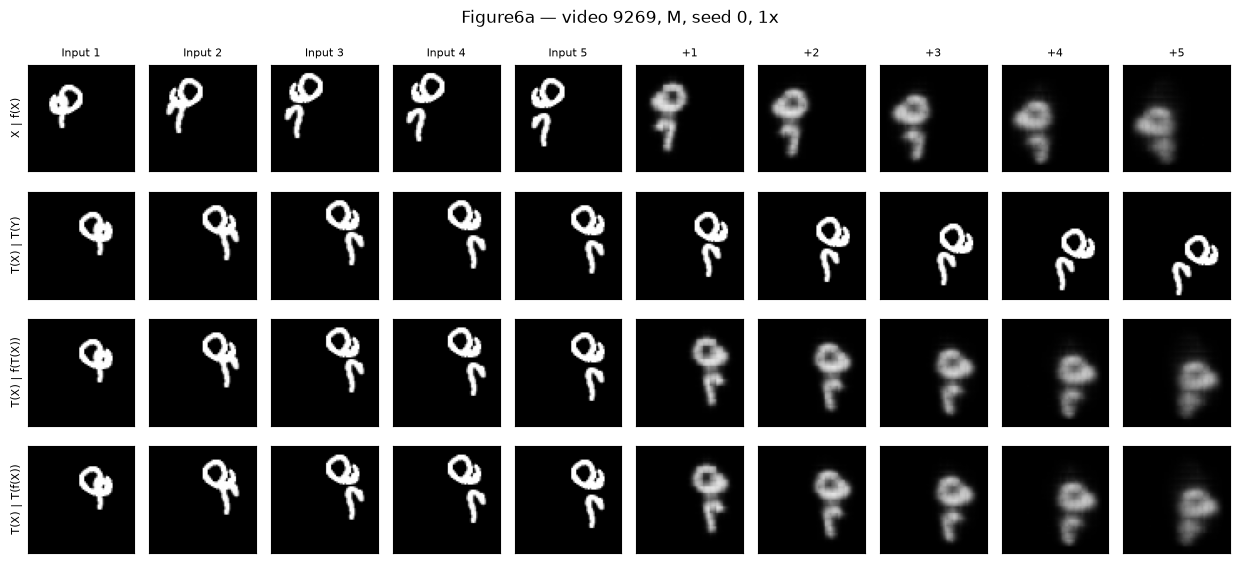

Figure6a, video 9269, transformation M, 1x, seed 0. GIF: Question2_normalized/artifacts/gifs/Figure6a_M_video9269.gif


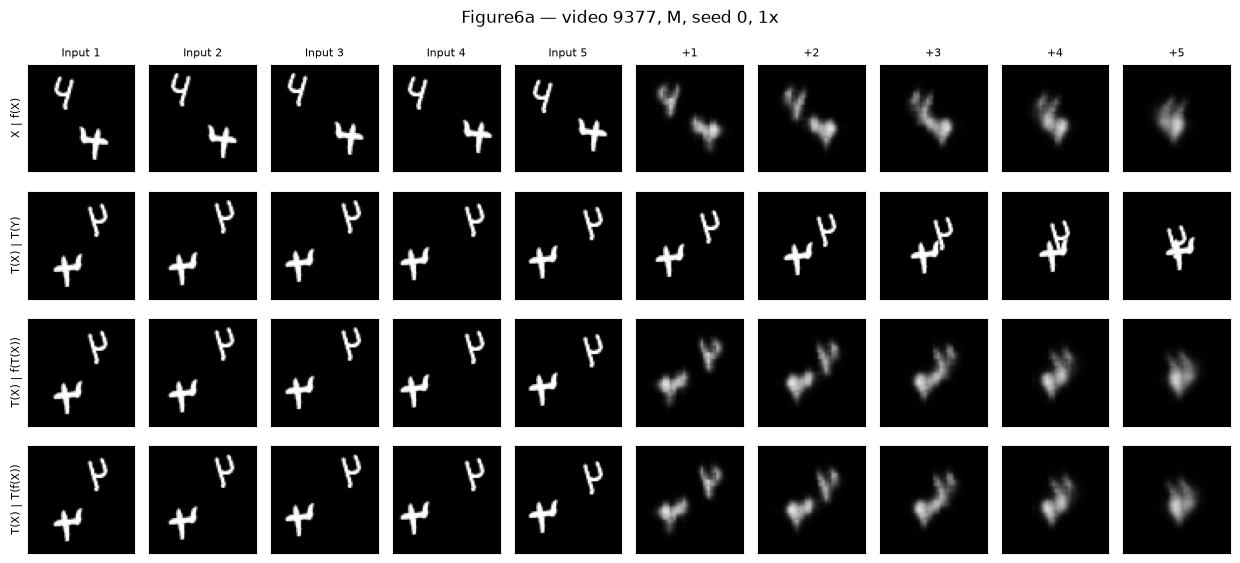

Figure6a, video 9377, transformation M, 1x, seed 0. GIF: Question2_normalized/artifacts/gifs/Figure6a_M_video9377.gif


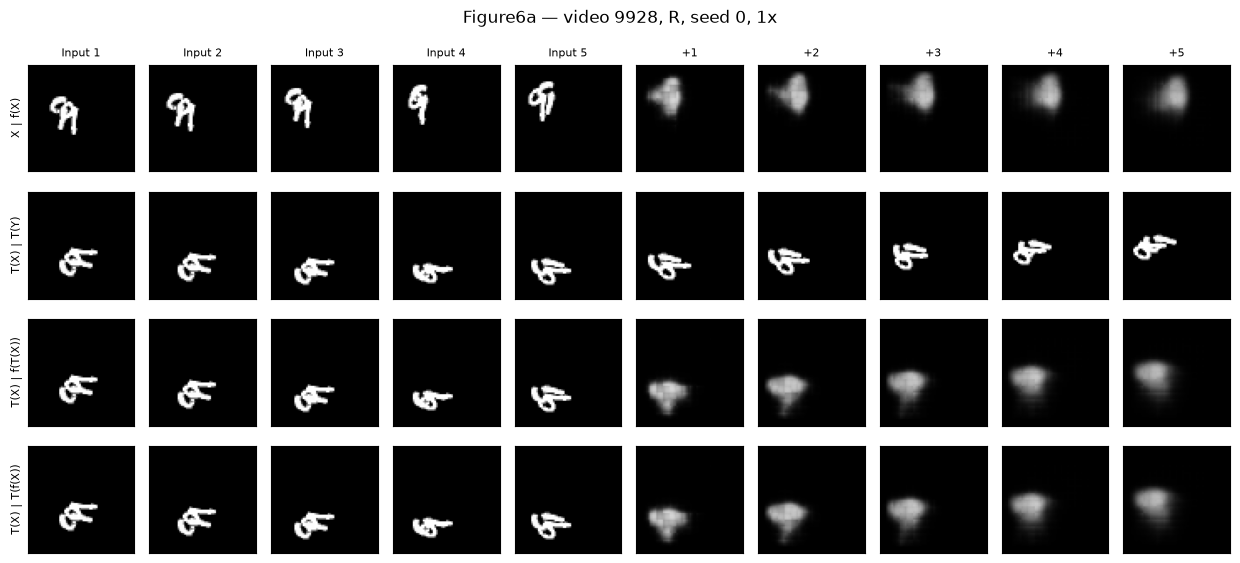

Figure6a, video 9928, transformation R, 1x, seed 0. GIF: Question2_normalized/artifacts/gifs/Figure6a_R_video9928.gif


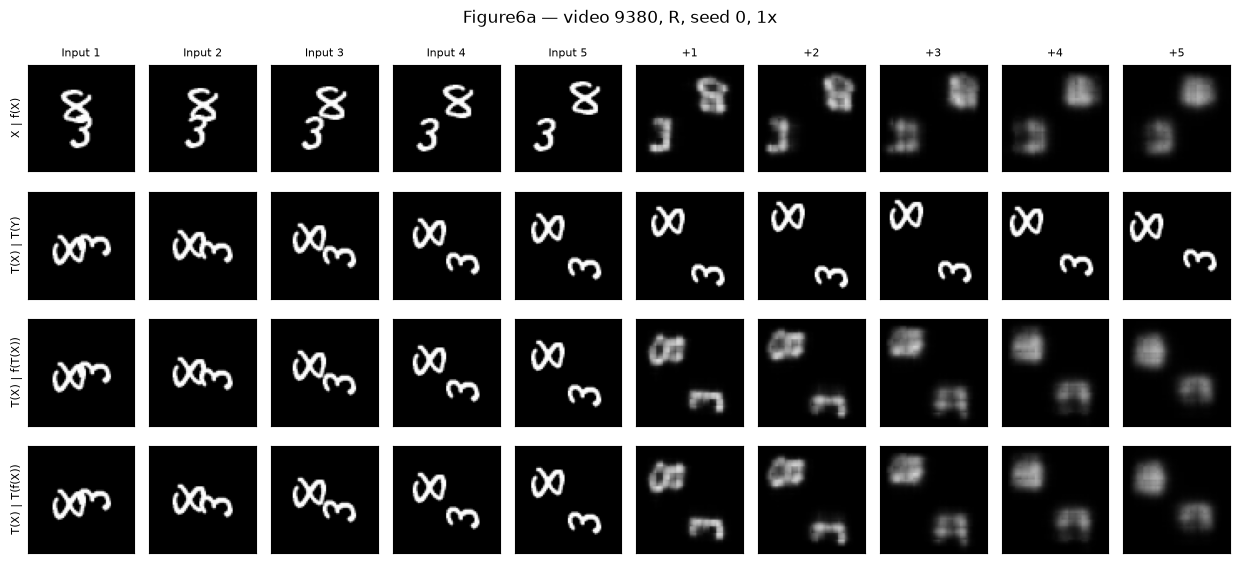

Figure6a, video 9380, transformation R, 1x, seed 0. GIF: Question2_normalized/artifacts/gifs/Figure6a_R_video9380.gif


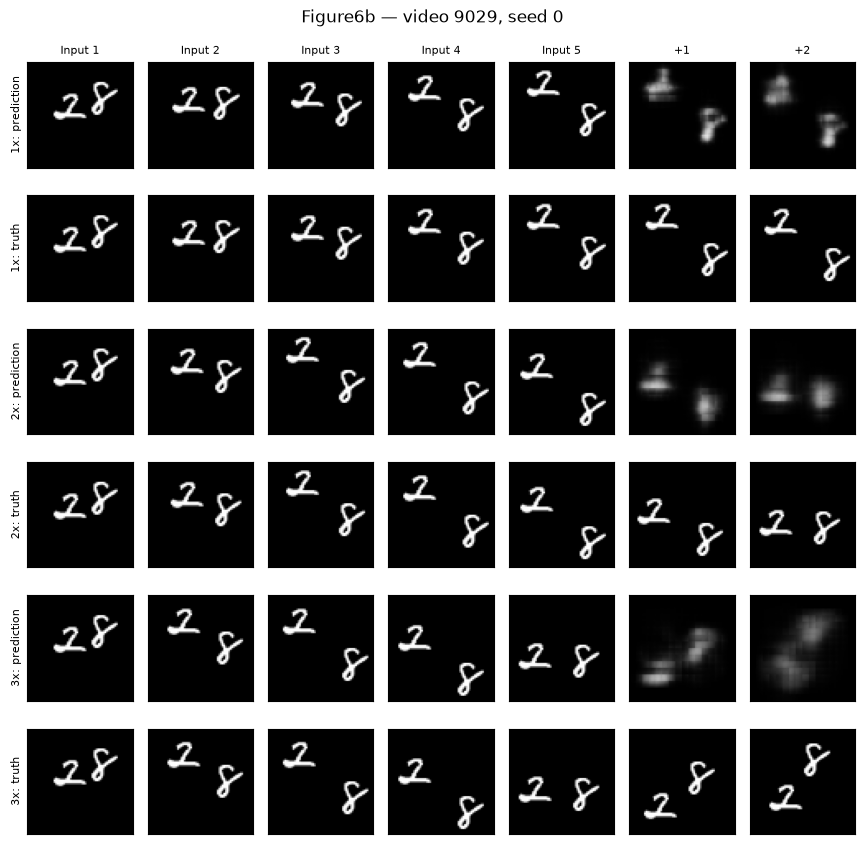

In [18]:
manifest = json.loads(selection_path.read_text())
final0 = Symmetrised(trained('D',0)).to(DEVICE).eval()
for item in manifest['figure3']:
    consistency_panel(final0, item['video'], item['transform'], 'Figure6a')
speed_panel(final0, manifest['figure5'], 'Figure6b')
